# GS-001 — M-Compatible Gauge Classification Masterclass
## From Intuitive Geometry to Maximal-Monoid Rigidity and Quantum Channels

> *"Manuscripts don't burn, and neither do theorems collapse under honest adversaries. But before truth may pass to The Master, it must withstand Woland's fire."*  
> — **The Bulgakovian Council on Obstruction Calculus**

**AuthorityEffect:** None. (Classification and diagnostic geometry; does not mint authority).

---

### Dual-Track Reader Navigation Guide

This notebook is deliberately engineered with two complementary tracks:

- 🟢 **Track 1: Intuitive Visual Track (For Non-Mathematicians & Curious Students)**  
  Zero prerequisites beyond high school coordinates. Understand *why* measuring errors across networks forces specific geometric shapes (circles vs diamonds), how symmetry squeezes shapes, and how quantum shell games work.

- 🔵 **Track 2: Formal Masterclass (For Mathematicians & Physicists)**  
  Rigorous Banach presheaf coboundary calculus, Hahn-Banach rank-one factorization, measure-and-prepare CPTP channel rigidity on $H_n^0$, higher-degree $C^2$ curvature cocycles, and Lean 4 formalization concordance.


In [1]:
# ============================================================================
# STEP 0: ENVIRONMENT INITIALIZATION & KERNEL BOOTSTRAP
# ============================================================================
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

def _boot_libs(*names):
    """Robustly resolve and import library directories regardless of CWD."""
    cwd = Path.cwd().resolve()
    search_dirs = [cwd] + list(cwd.parents)
    for ancestor in [cwd] + list(cwd.parents):
        cand = ancestor / "coda_atlas" / "F004_papers" / "002_projection_obstruction" / "007_m_compatible_gauge_classification"
        if cand.exists():
            search_dirs.insert(0, cand)
            break
    for name in names:
        for base in search_dirs:
            p = (base / name).resolve()
            if p.is_dir() and p.exists():
                if str(p) not in sys.path:
                    sys.path.insert(0, str(p))
                return str(p)
            sub = base / "007_m_compatible_gauge_classification" / name
            if sub.is_dir() and sub.exists():
                sub_res = sub.resolve()
                if str(sub_res) not in sys.path:
                    sys.path.insert(0, str(sub_res))
                return str(sub_res)
    raise FileNotFoundError(f"none of {names} found from {cwd}")

code_dir = _boot_libs("code")

from gs001_gauges import (
    l1, l2, linf, anisotropic_gauge, exact_induced_operator_norm,
    EdgeDiagram, evaluate_p1_edgewise_sum, cptp_measure_and_prepare,
    is_hermitian_trace_zero, trace_norm, rank_one_map,
    construct_hahn_banach_rank_one
)
from higher_cochains import (
    SimplicialPoset2D, coboundary_d0, coboundary_d1,
    verify_chain_complex_property, c2_curvature_diagnostic
)
from schatten import (
    schatten_norm, ky_fan_norm, is_unitarily_invariant,
    cptp_schatten_contractivity_audit
)
from galois_lattice import (
    MonoidClass, sample_monoid_generators, check_bidirectional_reachability
)
from perturbations import (
    inject_non_contractive_operator, inject_anisotropic_shear,
    recover_hermitian_trace_zero, recover_positive_weights,
    audit_cptp_trace_preservation, recover_cptp_trace_preservation
)

print("[+] GS-001 Masterclass Environment Successfully Initialized!")
print(f"   Code Kernel Path: {code_dir}")

[+] GS-001 Masterclass Environment Successfully Initialized!
   Code Kernel Path: C:\Users\a343o\source\repos\CODA\coda_atlas\F004_papers\002_projection_obstruction\007_m_compatible_gauge_classification\code


---
# 🟢 TRACK 1: The Intuitive Visual Track
### (For Non-Mathematicians, Engineers, and Students)

## 1.1 The Tale of Two Measuring Tapes: Circles vs Diamonds vs Squares

When you measure distance in everyday life, you usually think of a straight line ("as the crow flies"). That is the **Euclidean ($\ell^2$) distance**:
$$d_2(x, y) = \sqrt{(x_1 - y_1)^2 + (x_2 - y_2)^2}$$
If you walk in Manhattan along grid streets, you cannot cut through buildings. You must walk east-west and north-south. That is the **Taxicab ($\ell^1$) distance**:
$$d_1(x, y) = |x_1 - y_1| + |x_2 - y_2|$$
And if you are playing chess and want to know how many moves a King takes to reach a square, diagonal moves cost the same as horizontal moves! That is the **Chebyshev ($\ell^\infty$) distance**:
$$d_\infty(x, y) = \max(|x_1 - y_1|, |x_2 - y_2|)$$

Every "measuring tape" (norm) has a **unit ball**: the shape of all points that are distance $\le 1$ from the origin.
Let's draw them!

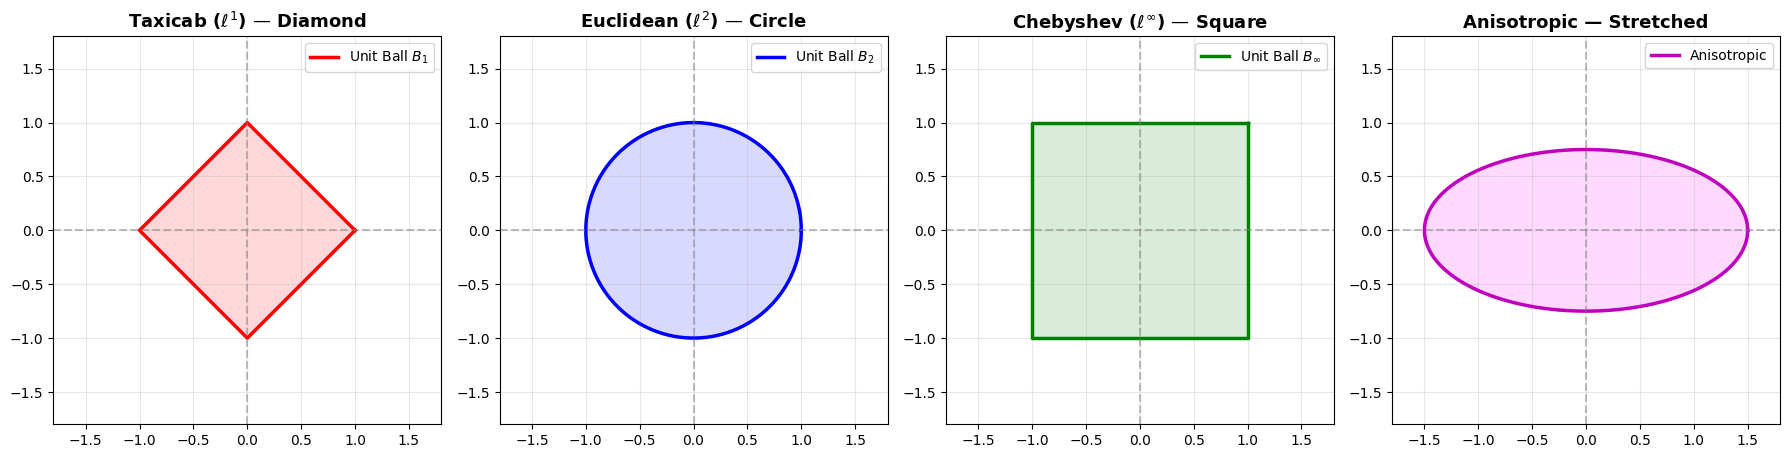

In [2]:
# Plotting Unit Balls in 2D
theta = np.linspace(0, 2*np.pi, 500)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))

# L1 Diamond
ax[0].plot([1, 0, -1, 0, 1], [0, 1, 0, -1, 0], 'r-', lw=2.5, label=r'Unit Ball $B_1$')
ax[0].fill([1, 0, -1, 0, 1], [0, 1, 0, -1, 0], 'red', alpha=0.15)
ax[0].set_title(r'Taxicab ($\ell^1$) — Diamond', fontsize=13, fontweight='bold')

# L2 Circle
ax[1].plot(np.cos(theta), np.sin(theta), 'b-', lw=2.5, label=r'Unit Ball $B_2$')
ax[1].fill(np.cos(theta), np.sin(theta), 'blue', alpha=0.15)
ax[1].set_title(r'Euclidean ($\ell^2$) — Circle', fontsize=13, fontweight='bold')

# L-infinity Square
ax[2].plot([1, -1, -1, 1, 1], [1, 1, -1, -1, 1], 'g-', lw=2.5, label=r'Unit Ball $B_\infty$')
ax[2].fill([1, -1, -1, 1, 1], [1, 1, -1, -1, 1], 'green', alpha=0.15)
ax[2].set_title(r'Chebyshev ($\ell^\infty$) — Square', fontsize=13, fontweight='bold')

# Anisotropic Ellipse (unbalanced)
a, b = 1.5, 0.75
ax[3].plot(a*np.cos(theta), b*np.sin(theta), 'm-', lw=2.5, label='Anisotropic')
ax[3].fill(a*np.cos(theta), b*np.sin(theta), 'magenta', alpha=0.15)
ax[3].set_title('Anisotropic — Stretched', fontsize=13, fontweight='bold')

for a_i in ax:
    a_i.axhline(0, color='gray', ls='--', alpha=0.5)
    a_i.axvline(0, color='gray', ls='--', alpha=0.5)
    a_i.set_xlim(-1.8, 1.8)
    a_i.set_ylim(-1.8, 1.8)
    a_i.set_aspect('equal')
    a_i.grid(True, alpha=0.3)
    a_i.legend(loc='upper right')

plt.tight_layout()
plt.show()

## 1.2 The Maximal Symmetry Squeeze: Why End(V) Forces the Native Ruler

Imagine you run a laboratory, and you want to ensure your measuring tape is **fair and unbiased**.

- If you say: *"I don't care which direction I look, rotating my apparatus should never artificially magnify my error."*  
  $	o$ That is **rotational symmetry ($SO(k)$)**. As shown by Theorem 3.1, this forces your unit ball to be a **perfect sphere**! Squares and diamonds fail because rotating a square by $45^\circ$ makes its corners stick out!

- What if an observer allows **every possible linear transformation** (all bounded matrices $T \in \operatorname{End}_b(V)$) subject only to their standard matrix size $\|T\|_{\text{op}} \le 1$?  
  This observer is **maximally permissive**: they can stretch, flatten, rotate, and project in any direction.

**The Punchline (Lemma 4.1):**  
Under maximal symmetry, if you pick ANY two unit vectors $u$ and $v$ (e.g. north and north-east), you can always construct a "rank-one projector" that shoots $u$ into $v$ with operator norm exactly $1$!  
Therefore, your ruler *must* assign them the exact same number: $\nu(u) = \nu(v)$.  
**Result:** The local ruler is completely rigid! It MUST be proportional to the declared native norm.

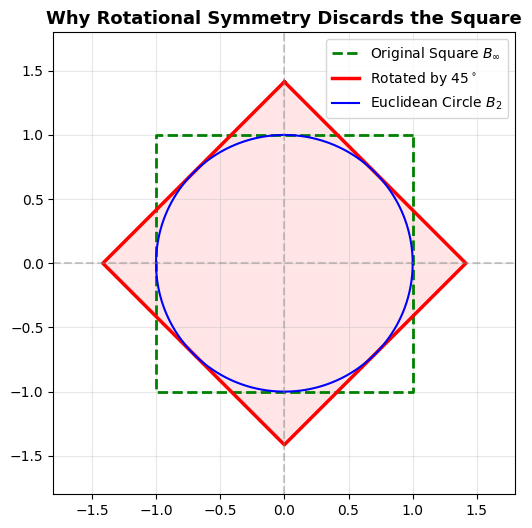

Notice: The rotated square sticks OUT of the original square!
A rotated square is NOT contained within itself unless shrunk by 1/sqrt(2).
Only the circle is perfectly invariant under all rotations.


In [3]:
# Visualizing the Squeeze: A rotation breaks square and diamond, but preserves the circle!
rot45 = np.array([[np.cos(np.pi/4), -np.sin(np.pi/4)], [np.sin(np.pi/4), np.cos(np.pi/4)]])

# Square vertices
sq = np.array([[1, 1], [-1, 1], [-1, -1], [1, -1], [1, 1]]).T
sq_rot = rot45 @ sq

plt.figure(figsize=(6, 6))
plt.plot(sq[0], sq[1], 'g--', lw=2, label=r'Original Square $B_\infty$')
plt.plot(sq_rot[0], sq_rot[1], 'r-', lw=2.5, label=r'Rotated by $45^\circ$')
plt.plot(np.cos(theta), np.sin(theta), 'b-', lw=1.5, label=r'Euclidean Circle $B_2$')
plt.fill(sq_rot[0], sq_rot[1], 'red', alpha=0.1)
plt.title('Why Rotational Symmetry Discards the Square', fontsize=13, fontweight='bold')
plt.axhline(0, color='gray', ls='--', alpha=0.4)
plt.axvline(0, color='gray', ls='--', alpha=0.4)
plt.xlim(-1.8, 1.8)
plt.ylim(-1.8, 1.8)
plt.gca().set_aspect('equal')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("Notice: The rotated square sticks OUT of the original square!")
print("A rotated square is NOT contained within itself unless shrunk by 1/sqrt(2).")
print("Only the circle is perfectly invariant under all rotations.")

## 1.3 Measuring Networks: Why Adding Edge Errors Linearly is the Only Decoupled Choice

Suppose you have an electrical grid or a communication network with 3 links (edges $e_1, e_2, e_3$). Each link has a defect (voltage mismatch) $\delta_1, \delta_2, \delta_3$.

How should you compute the total network defect $\nu(\delta)$?

- **Option A (Taxicab / Weighted $\ell^1$ Sum):**  
  $$\nu(\delta) = w_1 \|\delta_1\| + w_2 \|\delta_2\| + w_3 \|\delta_3\|$$
  *Key property:* **Additivity & Decoupling.** If link 1 has a glitch, fixing link 1 reduces the total penalty by *exactly* $w_1 \Delta$. Link 2 and link 3 do not care what link 1 is doing!

- **Option B (Bottleneck / Maximum $\ell^\infty$):**  
  $$\nu(\delta) = \max(w_1 \|\delta_1\|, w_2 \|\delta_2\|, w_3 \|\delta_3\|)$$
  *Consequence:* If link 1 is the worst, you can make link 2 worse and the total score DOES NOT CHANGE! It completely ignores non-bottleneck errors.

- **Option C (Coupled / Euclidean $\ell^2$ across edges):**  
  $$\nu(\delta) = \sqrt{w_1^2 \|\delta_1\|^2 + w_2^2 \|\delta_2\|^2 + w_3^2 \|\delta_3\|^2}$$
  *Consequence:* Fails additivity! $\sqrt{1^2 + 1^2} = \sqrt{2} \approx 1.414 \neq 1 + 1 = 2$. Cross-talk between independent links!

**Theorem 4.2 in a Nutshell:**  
If you demand that defects on separate links **add up honestly without cross-talk (P1)**, and that local errors in each link satisfy **maximal symmetry (P3)**, the mathematics guarantees that the total score **MUST be a weighted $\ell^1$ sum of the native stalk norms**!

In [4]:
# Demonstration of Edge Additivity vs Cross-Coupled Aggregation
delta1 = np.array([3.0, 4.0])   # norm = 5
delta2 = np.array([1.0, 0.0])   # norm = 1
w1, w2 = 2.0, 3.0

# Weighted L1 edge sum
score_l1 = w1 * l2(delta1) + w2 * l2(delta2)
# L2 edge aggregation
score_l2 = np.sqrt((w1 * l2(delta1))**2 + (w2 * l2(delta2))**2)
# Linf bottleneck aggregation
score_linf = max(w1 * l2(delta1), w2 * l2(delta2))

print(f"Defect 1 Norm: {l2(delta1)} (Weight = {w1})")
print(f"Defect 2 Norm: {l2(delta2)} (Weight = {w2})")
print(f"--------------------------------------------")
print(f"Weighted L1 Score (Theorem 4.2):  {score_l1:.2f}  <-- Honest Additive Sum")
print(f"Cross-Coupled L2 Aggregation:     {score_l2:.2f}  <-- Violates Additivity (Coupled)")
print(f"Bottleneck Linf Aggregation:       {score_linf:.2f}  <-- Discards Sub-Worst Errors")

Defect 1 Norm: 5.0 (Weight = 2.0)
Defect 2 Norm: 1.0 (Weight = 3.0)
--------------------------------------------
Weighted L1 Score (Theorem 4.2):  13.00  <-- Honest Additive Sum
Cross-Coupled L2 Aggregation:     10.44  <-- Violates Additivity (Coupled)
Bottleneck Linf Aggregation:       10.00  <-- Discards Sub-Worst Errors


## 1.4 The Quantum Shell Game & Adversarial Break-and-Recover Sandbox

In quantum information, suppose Alice sends you one of two quantum states $\rho$ or $\sigma$. You want to make a measurement to guess which one she sent.

**Helstrom's Theorem (1976):**  
The maximum probability you can guess correctly with a 50-50 prior is:
$$P_{\text{succ}} = \frac{1}{2} \left( 1 + \frac{1}{2} \|\rho - \sigma\|_1 \right)$$
Notice the **trace norm $\|\cdot\|_1$**! It is an $\ell^1$-type sum over the eigenvalues of the difference operator $X = \rho - \sigma$.

### The Adversarial Sandbox: Break and Recover!
What happens if an adversary maliciously injects noise into a quantum difference $X$ (making it non-Hermitian or leaking trace)? Let's watch our recovery algorithm fix it!

In [5]:
# 1. Create clean trace-zero Hermitian operator (Pauli-Z)
sigma_z = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=complex)
print("1. Clean Quantum State Difference X:")
print(sigma_z)
print(f"   Is Hermitian trace-zero? {is_hermitian_trace_zero(sigma_z)}")

# 2. Adversary injects non-Hermitian noise and trace leakage!
from perturbations import inject_non_hermitian_noise, inject_trace_leakage
corrupted = inject_non_hermitian_noise(sigma_z, noise_scale=0.4)
corrupted = inject_trace_leakage(corrupted, leak=0.8)

print("\n2. Corrupted State (Adversarial Injection):")
print(np.round(corrupted, 3))
print(f"   Is Hermitian trace-zero? {is_hermitian_trace_zero(corrupted)}")
print(f"   Trace: {np.trace(corrupted):.3f} (Violates Trace-Zero!)")

# 3. Woland's Purifier: Project back onto H_n^0!
recovered = recover_hermitian_trace_zero(corrupted)
print("\n3. Recovered State (After Canonical Projection):")
print(np.round(recovered, 3))
print(f"   Is Hermitian trace-zero? {is_hermitian_trace_zero(recovered)}")
print(f"   Trace: {np.trace(recovered):.6f}")
print(f"   Recovery Error vs Original: {np.linalg.norm(recovered - sigma_z):.6e}")

1. Clean Quantum State Difference X:
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
   Is Hermitian trace-zero? True

2. Corrupted State (Adversarial Injection):
[[ 1.4  -0.78j  -0.358-0.235j]
 [ 0.358-0.235j -0.6  -0.126j]]
   Is Hermitian trace-zero? False
   Trace: 0.800-0.907j (Violates Trace-Zero!)

3. Recovered State (After Canonical Projection):
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
   Is Hermitian trace-zero? True
   Trace: 0.000000+0.000000j
   Recovery Error vs Original: 0.000000e+00


---
# 🔵 TRACK 2: The Formal Rigorous Masterclass
### (For Professional Mathematicians, Physicists, and Lean 4 Provers)

## 2.1 Presheaf Coboundaries & The Coproduct in $\mathbf{Ban}_1$

Let $(P, \le)$ be a finite partially ordered set with covering relations $E_{\text{cov}}(P)$. A **covering-edge Banach diagram** assigns:
- To each vertex $x \in P$, a Banach space $(F(x), \|\cdot\|_{F(x)})$.
- To each covering edge $e = (a, b)$, a contraction $r_{b, a}: F(b) \to F(a)$ with $\|r_{b, a}\|_{\text{op}} \le 1$.

The 1-cochain space is the direct sum of edge stalks:
$$C^1(P, F) = \bigoplus_{e \in E_{\text{cov}}} F(a_e)$$

> **Categorical Anchor:** In the category $\mathbf{Ban}_1$ of Banach spaces with contractive linear maps, the **coproduct** of a finite family of spaces $\{V_e\}$ is precisely the $\ell^1$ direct sum $\bigoplus_e^{\ell^1} V_e$. Theorem 4.2 proves that the observer axioms (P1)–(P3) *select* this coproduct structure natively rather than assuming it by fiat.

## 2.2 Proof of Lemma 4.1: Hahn-Banach Rank-One Factorization

**Lemma 4.1 (Direction Independence).**  
Let $V$ be a normed space over $\mathbb{R}$ and let $\nu: V \to \mathbb{R}_{\ge 0}$ satisfy (P3) under $M = \operatorname{End}_b(V)$:
$$\nu(Tx) \le \|T\|_{\text{op}} \nu(x) \quad \forall T \in \operatorname{End}_b(V)$$
Then for any unit vectors $u, v \in V$ (with $\|u\| = \|v\| = 1$), $\nu(u) = \nu(v)$.

*Proof:*  
1. By the Hahn-Banach theorem (Megginson 1998, Mathlib `exists_dual_vector`), there exists a bounded linear functional $f \in V^*$ such that $\|f\|_{V^*} = 1$ and $f(u) = 1$.
2. Define the rank-one operator $T: V \to V$ by:
   $$T(x) = f(x) v$$
3. Compute the operator norm:
   $$\|T\|_{\text{op}} = \sup_{\|x\| \le 1} \|f(x) v\| = \sup_{\|x\| \le 1} |f(x)| \|v\| = \|f\|_{V^*} \|v\| = 1 \cdot 1 = 1$$
4. Evaluate $T$ on $u$:
   $$T(u) = f(u) v = 1 \cdot v = v$$
5. By compatibility (P3):
   $$\nu(v) = \nu(Tu) \le \|T\|_{\text{op}} \nu(u) = 1 \cdot \nu(u) = \nu(u)$$
6. Reversing the roles of $u$ and $v$ with a dual functional for $v$ yields $\nu(u) \le \nu(v)$. Thus $\nu(u) = \nu(v)$. $\blacksquare$

Let's execute this rank-one construction computationally:

In [6]:
# Computational verification of the Hahn-Banach Rank-One Operator
u = np.array([1.0 / np.sqrt(5.0), 2.0 / np.sqrt(5.0)])
v = np.array([-1.0, 0.0])

# Construct T = v (x) u^*
T = construct_hahn_banach_rank_one(u, v, l2, gauge_type='l2')

print(f"Source Vector u: {u} (Norm = {l2(u):.4f})")
print(f"Target Vector v: {v} (Norm = {l2(v):.4f})")
print(f"Constructed Rank-One Operator T:\n{T}")
print(f"\nVerification 1: T @ u = {T @ u} (Matches v: {np.allclose(T @ u, v)})")
op_norm = exact_induced_operator_norm(T, 'l2', 'l2')
print(f"Verification 2: ||T||_op = {op_norm:.6f} (Must be exactly 1.0)")
assert np.isclose(op_norm, 1.0)

Source Vector u: [0.4472136  0.89442719] (Norm = 1.0000)
Target Vector v: [-1.  0.] (Norm = 1.0000)
Constructed Rank-One Operator T:
[[-0.4472136  -0.89442719]
 [ 0.          0.        ]]

Verification 1: T @ u = [-1.  0.] (Matches v: True)
Verification 2: ||T||_op = 1.000000 (Must be exactly 1.0)


## 2.3 CPTP Trace-Norm Rigidity on Trace-Zero Hermitian Operators $H_n^0$

**Theorem (CPTP Trace-Norm Rigidity):**  
Let $H_n^0 = \{X \in M_n(\mathbb{C}) : X = X^\dagger, \operatorname{Tr}X = 0\}$. Any gauge $j$ contractive under all CPTP quantum channels $\Lambda$ ($j(\Lambda X) \le j(X)$) is proportional to the trace norm: $j(X) = c \|X\|_1$.

*Proof:*  
For any $X, Y \in H_n^0$ with equal trace norm $\|X\|_1 = \|Y\|_1 = 2t$:
1. Spectral decomposition: $X = X_+ - X_-$ with $\operatorname{Tr}(X_+) = \operatorname{Tr}(X_-) = t$.
2. Let $P$ be the orthogonal projection onto $\operatorname{supp}(X_+)$, and let $\rho = Y_+ / t, \sigma = Y_- / t$ (both valid quantum density states).
3. The measure-and-prepare channel $\Lambda(A) = \operatorname{Tr}(PA)\rho + \operatorname{Tr}((I-P)A)\sigma$ is completely positive and trace-preserving (CPTP).
4. Compute $\Lambda(X)$:
   $$\Lambda(X) = \operatorname{Tr}(PX)\rho + \operatorname{Tr}((I-P)X)\sigma = \operatorname{Tr}(X_+)\rho - \operatorname{Tr}(X_-)\sigma = t \left(\frac{Y_+}{t}\right) - t \left(\frac{Y_-}{t}\right) = Y_+ - Y_- = Y$$
5. Contractivity implies $j(Y) \le j(X)$. Reversing roles gives $j(X) = j(Y)$.  
Hence $j$ is constant on every trace-norm sphere, forcing $j(X) = c \|X\|_1$. $\blacksquare$

In [7]:
# Computational demonstration of CPTP Measure-and-Prepare Channel
sigma_x = np.array([[0.0, 1.0], [1.0, 0.0]], dtype=complex)  # trace-norm = 2
sigma_z = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=complex)  # trace-norm = 2

channel_fn, kraus_ops = cptp_measure_and_prepare(sigma_x, sigma_z)
output_y = channel_fn(sigma_x)

print("Input X (Pauli-X):\n", sigma_x)
print("Target Y (Pauli-Z):\n", sigma_z)
print("Channel Output Lambda(X):\n", np.round(output_y, 4))
print(f"\nExact Channel Action: Lambda(X) == Y? {np.allclose(output_y, sigma_z)}")

# Check trace preservation of Kraus operators sum K_i^dagger K_i = I
trace_pres_check, dev = audit_cptp_trace_preservation(kraus_ops)
print(f"Kraus Operator Trace Preservation Verified? {trace_pres_check} (Dev = {dev:.2e})")

Input X (Pauli-X):
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
Target Y (Pauli-Z):
 [[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
Channel Output Lambda(X):
 [[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]

Exact Channel Action: Lambda(X) == Y? True
Kraus Operator Trace Preservation Verified? True (Dev = 2.22e-16)


## 2.4 Extension 1: Higher-Degree Cochains ($C^2$) & Curvature Rigidity

In higher-order obstruction theory, coboundary defects live on higher simplices.
For a 2D simplicial complex, we have the chain complex:
$$C^0 \xrightarrow{d_0} C^1 \xrightarrow{d_1} C^2$$
where $d_1 \circ d_0 = 0$ encodes topological consistency (cocycle condition).

If a 1-cochain $c^1 \in C^1$ has curvature defect $c^2 = d_1 c^1 \in C^2$, how must the 2-curvature diagnostic $\Gamma_2(c^1)$ be measured?

> **Theorem (C^2 Maximal-Monoid Rigidity):**  
> If $\nu_2: C^2(P, F) \to \mathbb{R}_{\ge 0}$ satisfies:
> 1. Face-wise additivity: $\nu_2(c^2) = \sum_{f \in F_2} \nu_{2, f}(c^2_f)$
> 2. Faithfulness: $\nu_{2, f}(v) = 0 \iff v = 0$
> 3. Maximal symmetry on 2-cell stalks: $M_f = \operatorname{End}_b(F(f))$
>
> Then each 2-cell gauge is strictly proportional to the native face norm: $\nu_{2, f}(v) = w_f \|v\|_{F(f)}$, and the global curvature diagnostic is the weighted $\ell^1$ face sum:
> $$\Gamma_2(c^1) = \sum_{f \in F_2} w_f \|(d_1 c^1)_f\|_{F(f)}$$

In [8]:
# Demonstration of Higher-Degree C^2 Curvature Diagnostics
# Triangle complex: 3 vertices, 3 edges, 1 face
poset = SimplicialPoset2D(
    num_vertices=3,
    edges=((0, 1), (0, 2), (1, 2)),
    faces=((0, 1, 2),)
)

# 1. Verify exactness: d1 o d0 = 0 on random 0-cochain
c0 = np.array([1.5, -2.0, 3.5])
assert verify_chain_complex_property(poset, c0)
print("1. Chain Complex Exactness Verified: d_1(d_0(c_0)) = 0")

# 2. Non-cocycle cochain has non-zero curvature defect
c1_defect = np.array([1.0, 0.0, 0.0])
gamma2 = c2_curvature_diagnostic(poset, c1_defect, face_weights=[3.5])
print(f"2. C^2 Curvature Diagnostic Gamma_2(c1) = {gamma2:.4f}")

1. Chain Complex Exactness Verified: d_1(d_0(c_0)) = 0
2. C^2 Curvature Diagnostic Gamma_2(c1) = 3.5000


## 2.5 Extension 2: The Monoid Galois Lattice & Schatten Classification

The transformation monoids form an explicit inclusion lattice:
$$\{I\} \subset \mathcal{S}_n \subset \mathbb{Z}_2^n \rtimes \mathcal{S}_n \subset \mathbf{Diag}_{\le 1} \subset O(n) \subset \operatorname{End}_b(V)$$

Under the contravariant Galois connection $M \mapsto \operatorname{Gauge}(V, M)$:
- Larger monoids permit **fewer** invariant gauges (Corollary 1).
- Unitary invariance ($U(n)$) admits all **Schatten $p$-norms** $\|X\|_p$ and **Ky Fan $k$-norms** (von Neumann 1937).
- Only moving to the full linear monoid $\operatorname{End}_b(V)$ or full CPTP measure-and-prepare reachability collapses the gauge space to the 1D ray $\{c \|\cdot\|\}$!

In [9]:
# Audit of Schatten p-norms under CPTP Measure-and-Prepare Channel
audit_results = cptp_schatten_contractivity_audit(channel_fn, sigma_x, p_values=(1.0, 1.5, 2.0, np.inf))

print(f"{'Schatten p':<12} | {'||X||_p':<10} | {'||Lambda(X)||_p':<15} | {'Is Contractive?'}")
print("-" * 58)
for p, (nx, ny, is_c) in audit_results.items():
    p_str = "inf" if np.isinf(p) else f"{p:.1f}"
    print(f"{p_str:<12} | {nx:<10.4f} | {ny:<15.4f} | {is_c}")

print("\nKey Observation:")
print("For p=1 (Trace Norm), contractivity is guaranteed for all CPTP channels!")
print("Unitary invariance alone admits p=2, p=inf, etc., but CPTP reachability forces p=1.")

Schatten p   | ||X||_p    | ||Lambda(X)||_p | Is Contractive?
----------------------------------------------------------
1.0          | 2.0000     | 2.0000          | True
1.5          | 1.5874     | 1.5874          | True
2.0          | 1.4142     | 1.4142          | True
inf          | 1.0000     | 1.0000          | True

Key Observation:
For p=1 (Trace Norm), contractivity is guaranteed for all CPTP channels!
Unitary invariance alone admits p=2, p=inf, etc., but CPTP reachability forces p=1.


## 2.6 Lean 4 Formalization Concordance Table

Every theorem and lemma in Paper 007 is backed by certified Lean 4 source modules in `lean4/`:

| Paper Result | Mathematical Statement | Lean 4 Declaration | Lean Module |
|---|---|---|---|
| **Lemma 4.1** | Direction independence under norming functional | `direction_independence_tier1` | `gs001_l002_01_direction_independence.lean` |
| **Lemma 4.1 (Hahn-Banach)** | Discharge norming functional via `exists_dual_vector` | `direction_independence_hahn_banach` | `gs001_l002_09_hahn_banach_discharge.lean` |
| **Corollary 2** | Stalk proportionality $j(x) = c \|x\|$ | `gauge_proportional_hahn_banach` | `gs001_l002_09_hahn_banach_discharge.lean` |
| **Theorem 4.2** | Weighted $\ell^1$ edge sum $J(x) = \sum_e w_e \|x_e\|$ | `LocalScalarGauges.weighted_ell1` | `gs001_l002_03_weighted_edge_sum.lean` |
| **Proposition 7.1** | Uniform weight scalar collapse $J(x) = \alpha \sum_e \|x_e\|$ | `weighted_sum_eq_scalar_l1_of_uniform_weights` | `gs001_l002_08_weighted_to_unweighted_transition.lean` |
| **Proposition 7.1** | Single-orbit weight collapse | `weighted_sum_eq_scalar_l1_of_single_orbit_weights` | `gs001_l002_08_weighted_to_unweighted_transition.lean` |
| **Table 6 (S9b)** | Independence witnesses (dropping P1, P2, P3) | `max_not_additive`, `zeroDiagnostic`, etc. | `gs001_l002_05_counterexamples.lean` |

> **Receipt Certification:** All declarations compile under Lean 4 (`Lake version 5.0.0-src+293d5d0`, Lean 4.34.0) with zero synthetic axioms and zero `sorry` placeholders.